# 03 · Approach B: sequence model (BiGRU) on keypoint windows

Approach A summarises a whole clip into statistics, so it cannot see the **order** of movements: "reach to shelf → pause → hand to pocket" looks the same as the reverse. Here a small recurrent network reads the pose **frame by frame**.

- **Input per frame (85 numbers):** 34 normalised keypoint coordinates (17 joints × x, y), 34 velocities (how far each joint moved since the previous frame), 17 keypoint confidences (low = joint hidden or uncertain).
- **Windows:** clips are cut into **3.2-second windows** (32 frames at 10 fps). Every window inherits its clip's label. In each training epoch we draw up to **8 random windows per clip**, so the long DCSASS clips do not outweigh the short staged ones, and the model sees many slightly different views of each clip.
- **Augmentation (training only):** random left/right mirroring, ±10% scale jitter, small Gaussian noise.
- **Model:** linear embedding → 2-layer **bidirectional GRU** (hidden size 64) → average over time → probability of shoplifting.
- **Clip prediction:** run every window of a clip (step of 8 frames) and combine the window probabilities (**mean**, **max** or **top-3 mean**, chosen on validation).

Early stopping uses the validation clip-level ROC-AUC. The test set is **not** used here.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from torch import nn

import pose_utils as pu

torch.manual_seed(pu.SEED)
manifest = pu.load_manifest()

## 1. Load sequences

In [2]:
seqs = {p: pu.sequence_input(pu.clip_to_sequence(pu.load_extraction(c)))
        for p, c in zip(manifest["relative_path"], manifest["cache_path"])}
manifest["frames"] = manifest["relative_path"].map(lambda p: len(seqs[p]))
print("Per-frame input size:", next(iter(seqs.values())).shape[1])
manifest.groupby("source")["frames"].describe()

Per-frame input size: 85


,count,mean,std,min,25%,50%,75%,max
source,,,,,,,,
dcsass,28.0,731.428571,397.750287,320.0,320.0,640.0,960.0,1600.0
staged,179.0,110.765363,14.026889,52.0,106.0,109.0,115.0,206.0


In [3]:
def videos(split):
    m = manifest[manifest.split == split]
    return [(seqs[p], y) for p, y in zip(m["relative_path"], m["label"])]


train_videos, val_videos = videos("train"), videos("validation")
y_train = np.array([y for _, y in train_videos])
y_val = np.array([y for _, y in val_videos])
print(f"train clips: {len(train_videos)}, validation clips: {len(val_videos)}")

train clips: 144, validation clips: 30


## 2. Train

In [4]:
HIDDEN, LAYERS, DROPOUT = 64, 2, 0.3
WINDOWS_PER_VIDEO, BATCH, EPOCHS, PATIENCE = 8, 64, 80, 15
rng = np.random.default_rng(pu.SEED)


def epoch_windows(vids):
    """Up to WINDOWS_PER_VIDEO random augmented windows from every clip."""
    W, M, Y = [], [], []
    for x, y in vids:
        if len(x) <= pu.WINDOW:
            w, m = pu.make_windows(x)
            picks = [(w[0], m[0])]
        else:
            starts = rng.integers(0, len(x) - pu.WINDOW + 1, size=WINDOWS_PER_VIDEO)
            picks = [(x[s:s + pu.WINDOW], np.ones(pu.WINDOW, np.float32)) for s in starts]
        for w, m in picks:
            W.append(pu.augment(w, rng))
            M.append(m)
            Y.append(y)
    return torch.from_numpy(np.stack(W)), torch.from_numpy(np.stack(M)), torch.tensor(Y, dtype=torch.float32)


def clip_probs(model, vids, method="mean"):
    return np.array([pu.aggregate(pu.window_probs(model, x), method) for x, _ in vids])


model = pu.PoseGRU(hidden=HIDDEN, layers=LAYERS, dropout=DROPOUT)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-3)
pos_weight = torch.tensor((y_train == 0).sum() / (y_train == 1).sum(), dtype=torch.float32)
loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
print(f"{sum(p.numel() for p in model.parameters()):,} trainable parameters")

history, best_auc, best_state, best_epoch, waited = [], -1.0, None, 0, 0
for epoch in range(1, EPOCHS + 1):
    model.train()
    Xw, Mw, Yw = epoch_windows(train_videos)
    order = torch.randperm(len(Yw))
    total = 0.0
    for i in range(0, len(order), BATCH):
        idx = order[i:i + BATCH]
        optimizer.zero_grad()
        loss = loss_fn(model(Xw[idx], Mw[idx]), Yw[idx])
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        total += loss.item() * len(idx)
    p_val = clip_probs(model, val_videos)
    val_auc, val_acc = roc_auc_score(y_val, p_val), accuracy_score(y_val, p_val >= 0.5)
    history.append({"epoch": epoch, "train_loss": total / len(order), "val_auc": val_auc, "val_acc": val_acc})
    if val_auc > best_auc:
        best_auc, best_epoch, waited = val_auc, epoch, 0
        best_state = {k: v.clone() for k, v in model.state_dict().items()}
    else:
        waited += 1
    if epoch == 1 or epoch % 5 == 0:
        print(f"epoch {epoch:3d}  train_loss {history[-1]['train_loss']:.4f}  val_auc {val_auc:.3f}  val_acc {val_acc:.3f}")
    if waited >= PATIENCE:
        print(f"Early stopping at epoch {epoch}")
        break
model.load_state_dict(best_state)
history = pd.DataFrame(history)
history.to_csv(pu.RESULTS_DIR / "approach_b_history.csv", index=False)
print(f"Best epoch {best_epoch}: validation ROC-AUC {best_auc:.3f}")

130,049 trainable parameters


epoch   1  train_loss 0.6034  val_auc 0.566  val_acc 0.433


epoch   5  train_loss 0.5548  val_auc 0.647  val_acc 0.600


epoch  10  train_loss 0.4265  val_auc 0.747  val_acc 0.700


epoch  15  train_loss 0.3407  val_auc 0.751  val_acc 0.667


epoch  20  train_loss 0.3210  val_auc 0.724  val_acc 0.633


epoch  25  train_loss 0.3080  val_auc 0.701  val_acc 0.567


Early stopping at epoch 26
Best epoch 11: validation ROC-AUC 0.774


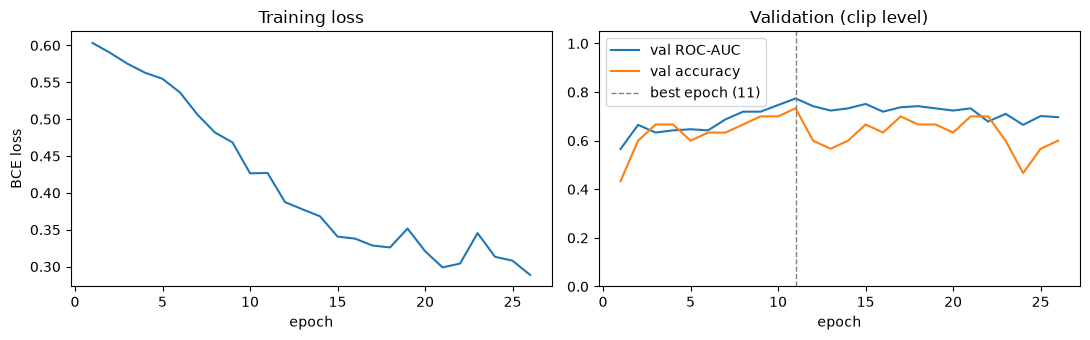

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(history["epoch"], history["train_loss"])
axes[0].set(title="Training loss", xlabel="epoch", ylabel="BCE loss")
axes[1].plot(history["epoch"], history["val_auc"], label="val ROC-AUC")
axes[1].plot(history["epoch"], history["val_acc"], label="val accuracy")
axes[1].axvline(best_epoch, ls="--", c="grey", lw=1, label=f"best epoch ({best_epoch})")
axes[1].set(title="Validation (clip level)", xlabel="epoch", ylim=(0, 1.05))
axes[1].legend()
plt.tight_layout()
plt.savefig(pu.FIGURES_DIR / "03_training_curves.png", dpi=150)
plt.show()

## 3. How to combine window predictions into a clip prediction

- **mean**: average over all windows (shoplifting has to be visible for much of the clip);
- **max**: the single most suspicious window decides (good when the theft is brief, but sensitive to one false alarm);
- **top-3 mean**: a compromise.

The method with the best validation F1 (ties broken by ROC-AUC) is kept.

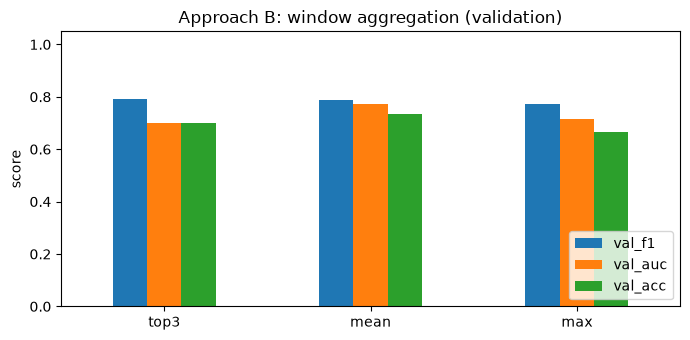

,aggregation,val_f1,val_auc,val_acc
0,top3,0.790698,0.701357,0.700000
1,mean,0.789474,0.773756,0.733333
2,max,0.772727,0.714932,0.666667


In [6]:
agg = []
for method in pu.AGGREGATIONS:
    p = clip_probs(model, val_videos, method)
    agg.append({"aggregation": method, "val_f1": f1_score(y_val, p >= 0.5),
                "val_auc": roc_auc_score(y_val, p), "val_acc": accuracy_score(y_val, p >= 0.5)})
agg = pd.DataFrame(agg).sort_values(["val_f1", "val_auc"], ascending=False).reset_index(drop=True)
agg.to_csv(pu.RESULTS_DIR / "approach_b_aggregation.csv", index=False)
ax = agg.set_index("aggregation")[["val_f1", "val_auc", "val_acc"]].plot.bar(rot=0, figsize=(7, 3.5), ylim=(0, 1.05))
ax.set(title="Approach B: window aggregation (validation)", ylabel="score", xlabel="")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(pu.FIGURES_DIR / "03_aggregation_comparison.png", dpi=150)
plt.show()
agg

In [7]:
best_agg = agg.iloc[0]
torch.save(model.state_dict(), pu.MODELS_DIR / "approach_b.pt")
meta = {"hidden": HIDDEN, "layers": LAYERS, "dropout": DROPOUT, "window": pu.WINDOW, "eval_stride": pu.EVAL_STRIDE,
        "aggregation": best_agg["aggregation"], "best_epoch": int(best_epoch),
        "val_f1": float(best_agg["val_f1"]), "val_auc": float(best_agg["val_auc"]), "val_acc": float(best_agg["val_acc"])}
(pu.MODELS_DIR / "approach_b_meta.json").write_text(json.dumps(meta, indent=2))
meta

{'hidden': 64,
 'layers': 2,
 'dropout': 0.3,
 'window': 32,
 'eval_stride': 8,
 'aggregation': 'top3',
 'best_epoch': 11,
 'val_f1': 0.7906976744186046,
 'val_auc': 0.7013574660633484,
 'val_acc': 0.7}

## 4. Where in a clip does the model see shoplifting?

Window-by-window probability across validation clips. For long CCTV clips this shows *when* the model gets suspicious.

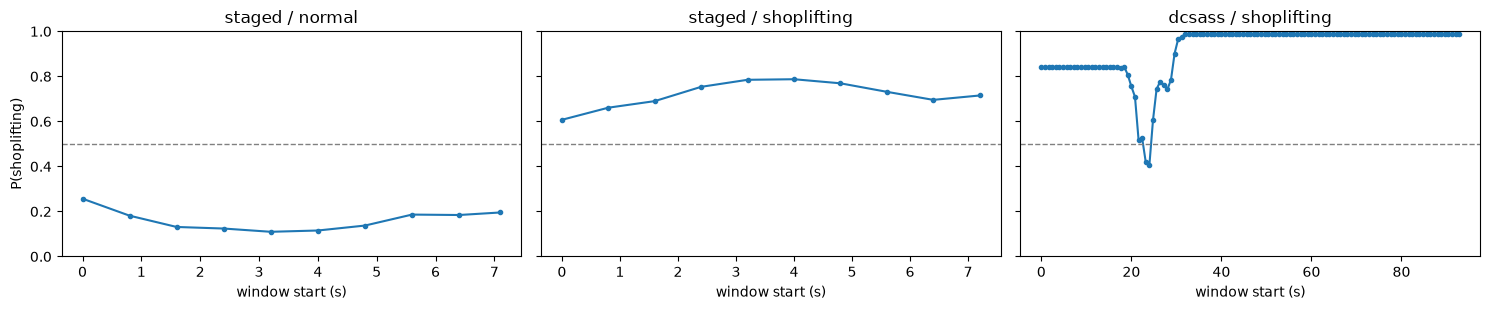

In [8]:
val_m = manifest[manifest.split == "validation"]
picks = pd.concat([val_m[(val_m.source == s) & (val_m.label_name == l)].head(1)
                   for s, l in [("staged", "normal"), ("staged", "shoplifting"), ("dcsass", "shoplifting")]])
fig, axes = plt.subplots(1, len(picks), figsize=(5 * len(picks), 3.2), sharey=True)
for ax, row in zip(np.atleast_1d(axes), picks.itertuples()):
    x = seqs[row.relative_path]
    p = pu.window_probs(model, x)
    starts = np.array(pu.window_starts(len(x))) / pu.TARGET_FPS
    ax.plot(starts, p, marker="o", ms=3)
    ax.axhline(0.5, ls="--", c="grey", lw=1)
    ax.set(title=f"{row.source} / {row.label_name}", xlabel="window start (s)", ylim=(0, 1))
np.atleast_1d(axes)[0].set_ylabel("P(shoplifting)")
plt.tight_layout()
plt.savefig(pu.FIGURES_DIR / "03_window_probabilities.png", dpi=150)
plt.show()